# E-commerce Customer Analytics: Retention, RFM and Revenue Concentration
**Author:** Kanat Mukhammedkanafiya, student at University of London (Data Science and Business Analytics)

**Data:** [Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii) (UCI Machine Learning Repository, CC BY 4.0). Every transaction of a UK online gift retailer from December 2009 to December 2011: about 1.07 million invoice lines, many of them from wholesale customers.

**Questions:**
1. How do revenue, orders and active customers change month by month?
2. How many customers come back after the first purchase (cohort retention)?
3. Which customer segments bring the revenue (RFM segmentation)?
4. How concentrated is revenue among the top customers?
5. What share of sales is returned, and which products are returned most?

**Stack:** Python, pandas, DuckDB (SQL: CTEs, window functions, `NTILE`, `QUALIFY`), Matplotlib.

In [1]:
import zipfile
from pathlib import Path
from urllib.request import urlretrieve

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

DATA_DIR = Path("data")
IMG_DIR = Path("images")
DATA_DIR.mkdir(exist_ok=True)
IMG_DIR.mkdir(exist_ok=True)

ZIP_URL = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"
ZIP_PATH = DATA_DIR / "online_retail_ii.zip"
XLSX_PATH = DATA_DIR / "online_retail_II.xlsx"
PARQUET_PATH = DATA_DIR / "online_retail_ii.parquet"

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.linestyle": "--", "grid.alpha": 0.4})
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Load the data
The raw file is a 45 MB Excel workbook with two sheets. It is downloaded once, and both sheets are combined and saved as Parquet. After that, every run reads the Parquet file in about a second.

In [2]:
if not PARQUET_PATH.exists():
    if not XLSX_PATH.exists():
        print("Downloading dataset from UCI...")
        urlretrieve(ZIP_URL, ZIP_PATH)
        with zipfile.ZipFile(ZIP_PATH) as z:
            z.extractall(DATA_DIR)
    sheets = pd.read_excel(XLSX_PATH, sheet_name=None,
                           dtype={"Invoice": str, "StockCode": str, "Description": str})
    pd.concat(sheets.values(), ignore_index=True).to_parquet(PARQUET_PATH, index=False)

con = duckdb.connect()  # in-memory database
con.execute(f"""
    CREATE OR REPLACE TABLE raw AS
    SELECT Invoice                        AS invoice,
           StockCode                      AS stock_code,
           Description                    AS description,
           Quantity                       AS quantity,
           InvoiceDate                    AS invoice_date,
           Price                          AS price,
           CAST("Customer ID" AS INTEGER) AS customer_id,
           Country                        AS country
    FROM read_parquet('{PARQUET_PATH.as_posix()}')
""")

sql = lambda q: con.sql(q).df()
sql("SELECT * FROM raw LIMIT 5")

,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom


## 2. Data quality check

In [3]:
sql("""
SELECT
    COUNT(*)                                        AS rows,
    MIN(invoice_date)                               AS first_date,
    MAX(invoice_date)                               AS last_date,
    COUNT(DISTINCT invoice)                         AS invoices,
    COUNT(DISTINCT customer_id)                     AS customers,
    COUNT(*) FILTER (WHERE customer_id IS NULL)     AS rows_without_customer,
    COUNT(*) FILTER (WHERE invoice LIKE 'C%')       AS cancellation_rows,
    COUNT(*) FILTER (WHERE quantity <= 0)           AS non_positive_quantity,
    COUNT(*) FILTER (WHERE price <= 0)              AS non_positive_price,
    COUNT(*) - (SELECT COUNT(*) FROM (SELECT DISTINCT * FROM raw)) AS exact_duplicates
FROM raw
""").T.rename(columns={0: "value"})

,value
rows,1067371
first_date,2009-12-01 07:45:00
last_date,2011-12-09 12:50:00
invoices,53628
customers,5942
rows_without_customer,243007
cancellation_rows,19494
non_positive_quantity,22950
non_positive_price,6207
exact_duplicates,34335


Codes that are not products also appear in the data: postage, Amazon fees, bank charges, manual adjustments, samples, test items and gift vouchers. They are not product sales, so they are excluded from the analysis.

In [4]:
NON_PRODUCT = """
    stock_code IN ('POST', 'DOT', 'M', 'm', 'C2', 'D', 'S', 'B', 'BANK CHARGES',
                   'ADJUST', 'ADJUST2', 'AMAZONFEE', 'PADS', 'CRUK')
    OR stock_code ILIKE 'gift_%'
    OR stock_code ILIKE 'TEST%'
"""

sql(f"""
SELECT stock_code, ANY_VALUE(description) AS description, COUNT(*) AS rows,
       ROUND(SUM(quantity * price), 0) AS amount
FROM raw WHERE {NON_PRODUCT}
GROUP BY stock_code ORDER BY rows DESC
""")

,stock_code,description,rows,amount
0,POST,POSTAGE,2122,"112,341.00"
1,DOT,DOTCOM POSTAGE,1446,"322,647.00"
2,M,Manual,1421,"-82,796.00"
3,C2,CARRIAGE,282,"13,386.00"
4,D,Discount,177,"-13,485.00"
5,S,SAMPLES,104,"-6,066.00"
6,BANK CHARGES,Bank Charges,102,"-35,563.00"
7,ADJUST,Adjustment by Peter on 24/05/2010 1,67,"6,835.00"
8,AMAZONFEE,AMAZON FEE,43,"-260,764.00"
9,gift_0001_20,Dotcomgiftshop Gift Voucher £20.00,29,471.00


## 3. Cleaning
| Rule | Why |
|---|---|
| Remove exact duplicate rows | The two Excel sheets overlap in early December 2010 |
| Keep rows with a customer ID | Customer-level metrics need a known customer |
| Remove non-product codes | Fees, postage and adjustments are not product sales |
| Remove order-entry errors: a line cancelled by the same customer within 1 hour, with the same product, quantity and price | Removes, for example, an 80,995-unit order (£168k) cancelled 12 minutes later. Otherwise it would count as revenue and as a return |
| Sales: not a cancellation, `quantity > 0`, `price > 0` | Clean purchase lines |
| Returns: cancellation invoices (`C...`) | Analysed separately in section 8 |

In [5]:
con.execute(f"""
CREATE OR REPLACE TABLE base AS
SELECT ROW_NUMBER() OVER () AS line_id, *
FROM (SELECT DISTINCT * FROM raw
      WHERE customer_id IS NOT NULL AND NOT ({NON_PRODUCT}));

-- Order-entry errors: a purchase line and its cancellation within one hour
CREATE OR REPLACE TABLE entry_errors AS
SELECT s.line_id AS sale_line, r.line_id AS cancel_line, s.quantity * s.price AS value
FROM base s
JOIN base r
  ON  r.customer_id = s.customer_id
  AND r.stock_code  = s.stock_code
  AND r.price       = s.price
  AND r.quantity    = -s.quantity
  AND r.invoice LIKE 'C%' AND s.invoice NOT LIKE 'C%'
  AND r.invoice_date BETWEEN s.invoice_date AND s.invoice_date + INTERVAL 1 HOUR
QUALIFY ROW_NUMBER() OVER (PARTITION BY s.line_id ORDER BY r.invoice_date) = 1;

CREATE OR REPLACE TABLE sales AS
SELECT *, quantity * price AS revenue
FROM base
WHERE invoice NOT LIKE 'C%' AND quantity > 0 AND price > 0
  AND line_id NOT IN (SELECT sale_line FROM entry_errors);

CREATE OR REPLACE TABLE returns AS
SELECT *, -quantity * price AS returned_value
FROM base
WHERE invoice LIKE 'C%' AND quantity < 0
  AND line_id NOT IN (SELECT cancel_line FROM entry_errors);
""")

print(sql("SELECT COUNT(*) AS entry_error_lines, ROUND(SUM(value), 0) AS value_removed FROM entry_errors"))

funnel = sql("""
SELECT 'raw rows' AS step, COUNT(*) AS rows FROM raw
UNION ALL SELECT 'after dedup, known customer, products only', COUNT(*) FROM base
UNION ALL SELECT 'clean sales lines', COUNT(*) FROM sales
UNION ALL SELECT 'return lines', COUNT(*) FROM returns
""")
funnel

   entry_error_lines  value_removed
0               1039     318,158.00


,step,rows
0,raw rows,1067371
1,"after dedup, known customer, products only",794225
2,clean sales lines,775540
3,return lines,16600


In [6]:
sql("""
SELECT COUNT(DISTINCT customer_id)        AS customers,
       COUNT(DISTINCT invoice)            AS orders,
       COUNT(DISTINCT stock_code)         AS products,
       COUNT(DISTINCT country)            AS countries,
       ROUND(SUM(revenue), 0)             AS revenue_gbp
FROM sales
""")

,customers,orders,products,countries,revenue_gbp
0,5850,36492,4615,41,"16,750,425.00"


## 4. Monthly performance
December 2011 only has data until the 9th, so it is left out of the trend charts.

In [7]:
monthly = sql("""
WITH first_purchase AS (
    SELECT customer_id, MIN(DATE_TRUNC('month', invoice_date)) AS first_month
    FROM sales GROUP BY customer_id
),
m AS (
    SELECT DATE_TRUNC('month', s.invoice_date)                     AS month,
           SUM(s.revenue)                                          AS revenue,
           COUNT(DISTINCT s.invoice)                               AS orders,
           COUNT(DISTINCT s.customer_id)                           AS active_customers,
           COUNT(DISTINCT s.customer_id) FILTER (
               WHERE DATE_TRUNC('month', s.invoice_date) = f.first_month) AS new_customers
    FROM sales s JOIN first_purchase f USING (customer_id)
    GROUP BY 1
)
SELECT *, revenue / orders AS avg_order_value
FROM m
WHERE month < DATE '2011-12-01'
ORDER BY month
""")
monthly["month"] = pd.to_datetime(monthly["month"])
monthly.tail(12)

,month,revenue,orders,active_customers,new_customers,avg_order_value
12,2010-12-01,"563,211.08",1391,884,76,404.90
13,2011-01-01,"484,979.21",980,738,72,494.88
14,2011-02-01,"442,126.64",989,756,125,447.04
15,2011-03-01,"579,815.07",1307,972,179,443.62
16,2011-04-01,"453,259.09",1136,853,106,399.00
17,2011-05-01,"659,115.31",1540,1054,111,428.00
18,2011-06-01,"652,476.23",1384,988,108,471.44
19,2011-07-01,"590,958.90",1320,945,101,447.70
20,2011-08-01,"630,927.66",1265,933,107,498.76
21,2011-09-01,"938,166.51",1735,1257,188,540.73


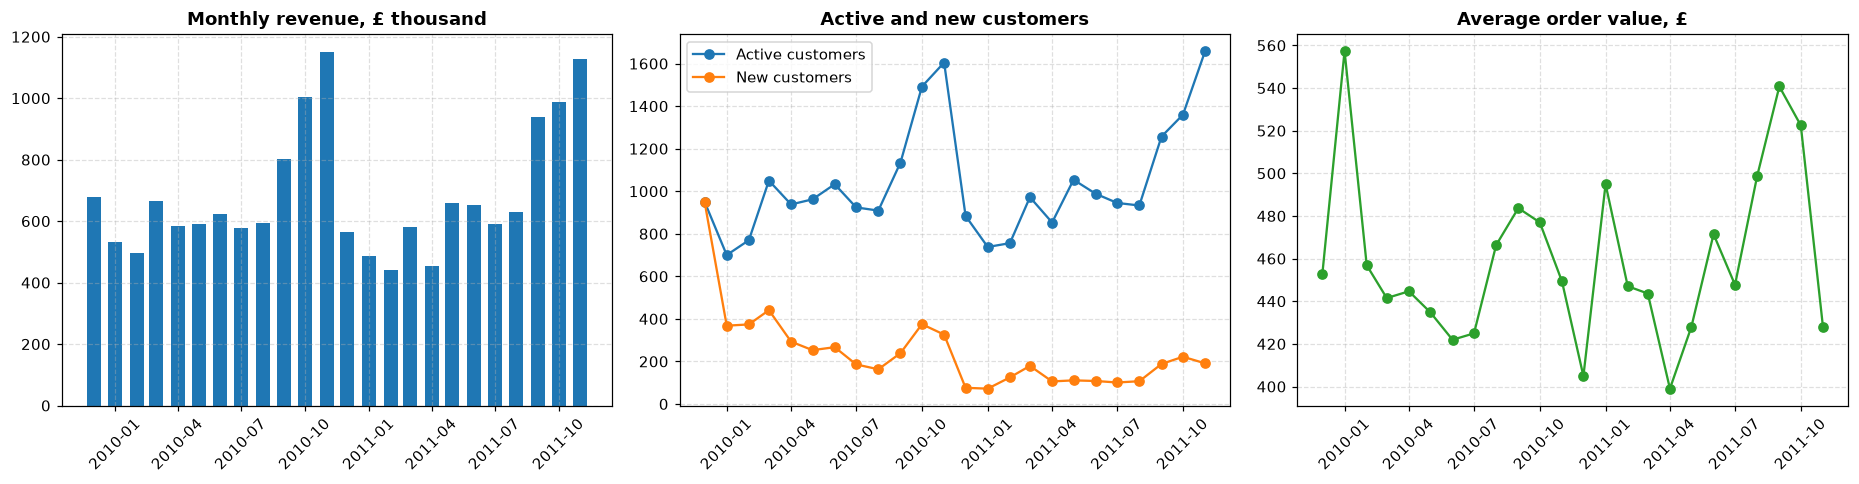

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].bar(monthly["month"], monthly["revenue"] / 1000, width=20, color="#1f77b4")
axes[0].set_title("Monthly revenue, £ thousand", fontweight="bold")

axes[1].plot(monthly["month"], monthly["active_customers"], marker="o", label="Active customers")
axes[1].plot(monthly["month"], monthly["new_customers"], marker="o", label="New customers")
axes[1].set_title("Active and new customers", fontweight="bold")
axes[1].legend()

axes[2].plot(monthly["month"], monthly["avg_order_value"], marker="o", color="#2ca02c")
axes[2].set_title("Average order value, £", fontweight="bold")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(IMG_DIR / "monthly_kpis.png", bbox_inches="tight")
plt.show()

In [9]:
yoy = sql("""
SELECT YEAR(invoice_date) AS year,
       ROUND(SUM(revenue), 0) AS revenue,
       COUNT(DISTINCT customer_id) AS customers
FROM sales
WHERE MONTH(invoice_date) BETWEEN 1 AND 11 AND YEAR(invoice_date) IN (2010, 2011)
GROUP BY 1 ORDER BY 1
""")
yoy["revenue_growth_pct"] = yoy["revenue"].pct_change() * 100
yoy  # January-November, same months in both years

,year,revenue,customers,revenue_growth_pct
0,2010,"7,619,375.00",4124,NaN
1,2011,"7,547,433.00",4167,-0.94


## 5. Cohort retention
Customers are grouped by the month of their first purchase. Retention for month *N* is the share of the cohort that bought again *N* months later.

Caveat: the data starts in December 2009, so the December 2009 cohort also contains older customers who were already buying before. That makes its retention look higher.

In [10]:
cohorts = sql("""
WITH customer_months AS (
    SELECT DISTINCT customer_id, DATE_TRUNC('month', invoice_date) AS month
    FROM sales
    WHERE invoice_date < DATE '2011-12-01'
),
with_cohort AS (
    SELECT customer_id, month,
           MIN(month) OVER (PARTITION BY customer_id) AS cohort
    FROM customer_months
)
SELECT cohort,
       DATE_DIFF('month', cohort, month) AS month_number,
       COUNT(*) AS customers
FROM with_cohort
GROUP BY ALL
""")

pivot = cohorts.pivot(index="cohort", columns="month_number", values="customers").sort_index()
retention = pivot.div(pivot[0], axis=0) * 100
retention.index = pd.to_datetime(retention.index).strftime("%Y-%m")
cohort_sizes = pivot[0]
retention.iloc[:, :13].round(1)

month_number,0,1,2,3,4,5,6,7,8,9,10,11,12
cohort,,,,,,,,,,,,,
2009-12,100.00,34.90,33.30,42.50,37.90,36.00,37.60,34.40,33.60,36.10,42.20,49.60,37.60
2010-01,100.00,21.50,31.80,31.50,26.90,31.00,26.90,23.40,28.50,32.60,30.70,17.90,22.80
2010-02,100.00,23.50,22.70,29.40,24.60,19.50,19.30,28.90,25.70,27.80,11.50,12.60,15.00
2010-03,100.00,19.00,23.10,24.30,23.10,20.40,24.70,30.60,27.70,10.90,11.30,14.50,20.00
2010-04,100.00,19.10,19.10,16.00,18.40,22.20,27.60,26.60,10.60,10.90,7.50,14.00,14.30
2010-05,100.00,15.40,17.00,17.80,17.80,25.70,21.30,12.60,5.90,8.30,11.50,13.40,15.40
2010-06,100.00,17.60,18.70,20.60,23.20,28.50,12.70,9.00,8.20,11.20,10.50,13.90,15.00
2010-07,100.00,15.60,18.30,29.60,29.00,14.00,11.30,15.10,14.50,11.30,13.40,14.50,12.90
2010-08,100.00,19.60,28.80,32.50,16.60,11.70,9.80,12.90,13.50,12.90,12.90,11.70,14.70


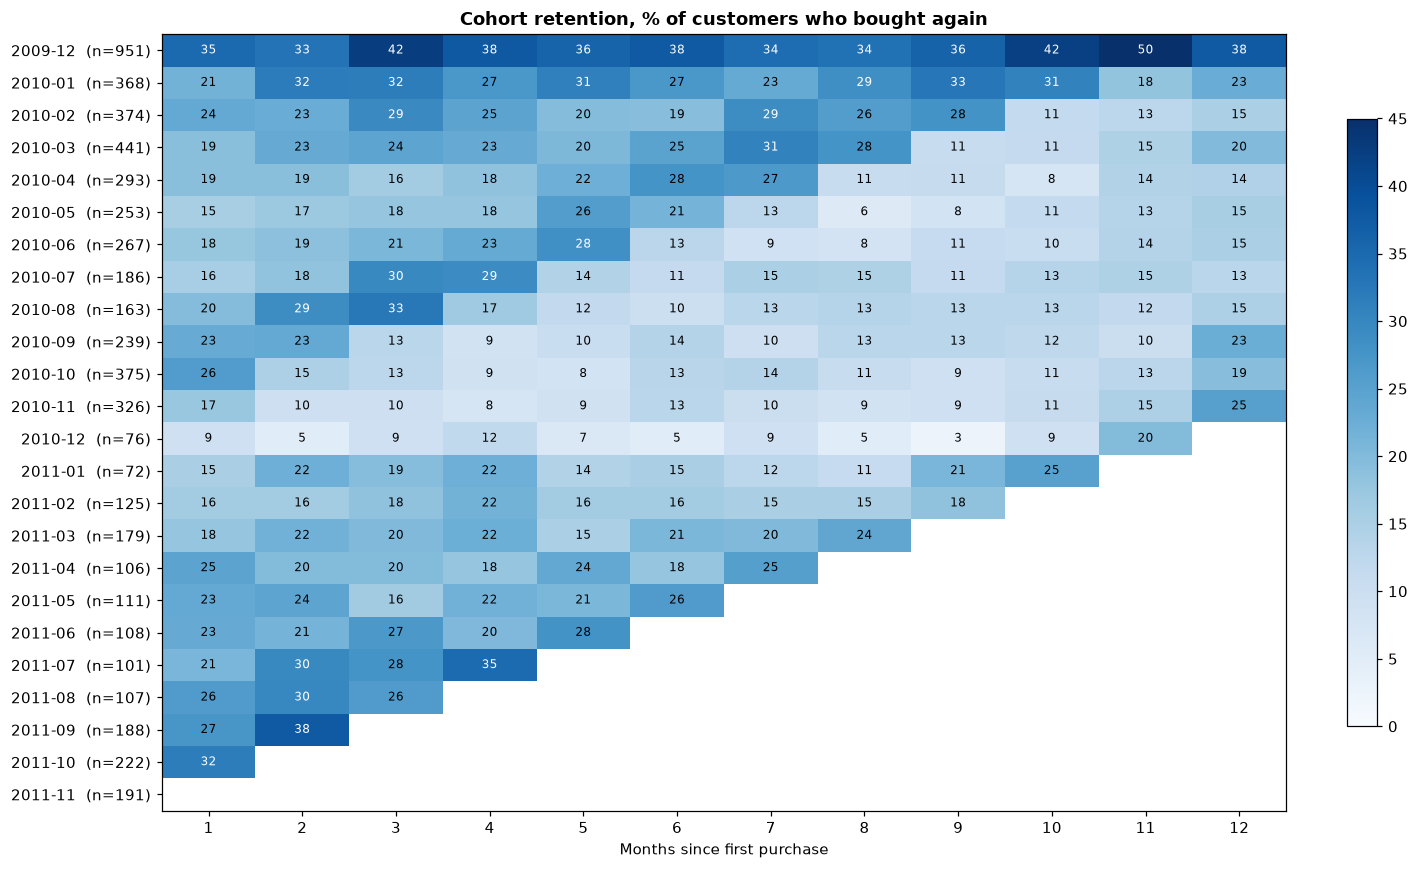

In [11]:
ret = retention.iloc[:, 1:13]  # months 1-12
fig, ax = plt.subplots(figsize=(13, 8))
im = ax.imshow(ret.values, cmap="Blues", aspect="auto", vmin=0, vmax=45)
ax.set_xticks(range(ret.shape[1]), ret.columns)
ax.set_yticks(range(ret.shape[0]), [f"{c}  (n={int(n)})" for c, n in zip(ret.index, cohort_sizes.values)])
for i in range(ret.shape[0]):
    for j in range(ret.shape[1]):
        v = ret.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if v > 28 else "black")
ax.set_xlabel("Months since first purchase")
ax.set_title("Cohort retention, % of customers who bought again", fontweight="bold")
ax.grid(False)
plt.colorbar(im, ax=ax, fraction=0.025)
plt.tight_layout()
plt.savefig(IMG_DIR / "cohort_retention.png", bbox_inches="tight")
plt.show()

In [12]:
# Average retention of cohorts that are not left-censored (first purchase from Jan 2010)
avg_ret = retention.loc[retention.index >= "2010-01", [1, 3, 6, 12]].mean().round(1)
avg_ret.index = [f"month {m}" for m in avg_ret.index]
avg_ret.to_frame("avg_retention_pct")

,avg_retention_pct
month 1,20.60
month 3,21.00
month 6,17.30
month 12,17.90


## 6. RFM segmentation
For every customer, as of the day after the last transaction:
- **Recency:** days since the last purchase
- **Frequency:** number of orders
- **Monetary:** total spend

Each metric is split into quintiles with `NTILE(5)`. A score of 5 is the best: most recent, most frequent, highest spend. Segments are assigned from the R score and the average of the F and M scores.

In [13]:
rfm = sql("""
WITH snapshot AS (SELECT MAX(invoice_date)::DATE + 1 AS d FROM sales),
base AS (
    SELECT customer_id,
           DATE_DIFF('day', MAX(invoice_date)::DATE, (SELECT d FROM snapshot)) AS recency,
           COUNT(DISTINCT invoice)                                             AS frequency,
           SUM(revenue)                                                        AS monetary
    FROM sales GROUP BY customer_id
),
scored AS (
    SELECT *,
           NTILE(5) OVER (ORDER BY recency DESC) AS r,
           NTILE(5) OVER (ORDER BY frequency)    AS f,
           NTILE(5) OVER (ORDER BY monetary)     AS m
    FROM base
)
SELECT *,
       CASE
           WHEN r >= 4 AND (f + m) / 2.0 >= 4   THEN 'Champions'
           WHEN r >= 3 AND (f + m) / 2.0 >= 3   THEN 'Loyal'
           WHEN r >= 4 AND (f + m) / 2.0 >= 2   THEN 'Potential loyalists'
           WHEN r >= 4                          THEN 'New / one-off'
           WHEN r <= 2 AND (f + m) / 2.0 >= 4   THEN 'Cannot lose them'
           WHEN r <= 3 AND (f + m) / 2.0 >= 3   THEN 'At risk'
           WHEN r = 3                           THEN 'Need attention'
           ELSE 'Hibernating / lost'
       END AS segment
FROM scored
""")

segments = (rfm.groupby("segment")
               .agg(customers=("customer_id", "count"),
                    revenue=("monetary", "sum"),
                    avg_recency_days=("recency", "mean"),
                    avg_orders=("frequency", "mean"),
                    avg_spend=("monetary", "mean"))
               .sort_values("revenue", ascending=False))
segments["customers_pct"] = segments["customers"] / segments["customers"].sum() * 100
segments["revenue_pct"] = segments["revenue"] / segments["revenue"].sum() * 100
segments.round(1)

,customers,revenue,avg_recency_days,avg_orders,avg_spend,customers_pct,revenue_pct
segment,,,,,,,
Champions,1328,"11,691,013.80",19.80,16.60,"8,803.50",22.70,69.80
Loyal,1205,"2,539,907.00",71.30,5.70,"2,107.80",20.60,15.20
Cannot lose them,247,"1,021,541.00",349.20,8.70,"4,135.80",4.20,6.10
Hibernating / lost,1661,"576,036.70",451.60,1.40,346.80,28.40,3.40
At risk,432,"531,141.20",367.90,3.60,"1,229.50",7.40,3.20
Need attention,473,"202,782.20",109.30,1.70,428.70,8.10,1.20
Potential loyalists,322,"150,578.50",27.00,2.10,467.60,5.50,0.90
New / one-off,182,"37,424.20",34.20,1.10,205.60,3.10,0.20


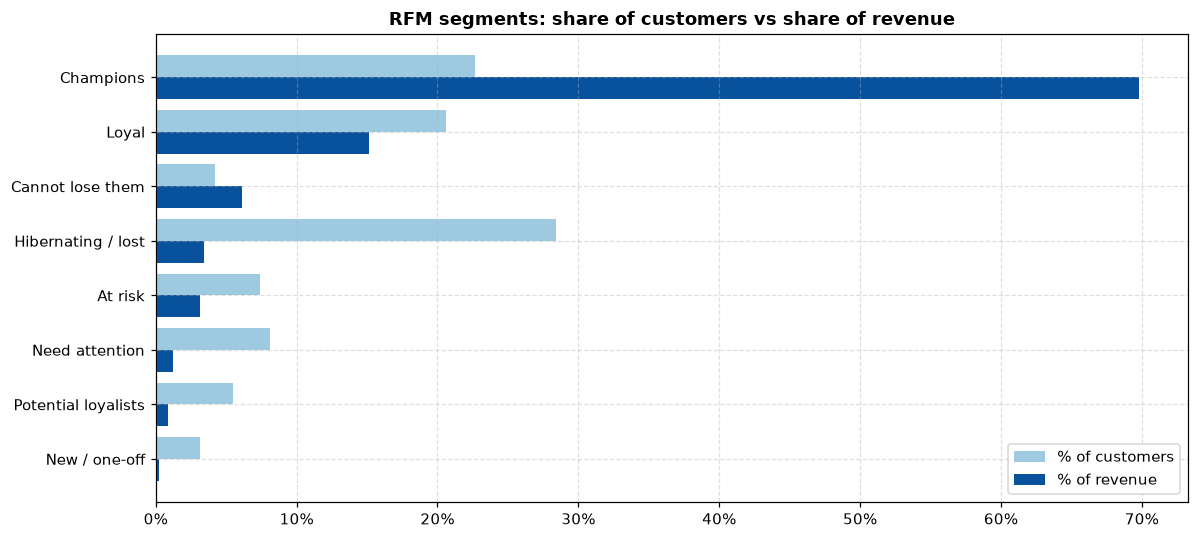

In [14]:
fig, ax = plt.subplots(figsize=(11, 5))
y = np.arange(len(segments))
ax.barh(y - 0.2, segments["customers_pct"], height=0.4, label="% of customers", color="#9ecae1")
ax.barh(y + 0.2, segments["revenue_pct"], height=0.4, label="% of revenue", color="#08519c")
ax.set_yticks(y, segments.index)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("RFM segments: share of customers vs share of revenue", fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(IMG_DIR / "rfm_segments.png", bbox_inches="tight")
plt.show()

## 7. Revenue concentration

In [15]:
conc = sql("""
WITH c AS (
    SELECT customer_id, SUM(revenue) AS revenue FROM sales GROUP BY customer_id
),
ranked AS (
    SELECT revenue,
           ROW_NUMBER() OVER (ORDER BY revenue DESC) AS rnk,
           COUNT(*)     OVER ()                      AS n,
           SUM(revenue) OVER ()                      AS total
    FROM c
)
SELECT
    ROUND(100 * SUM(revenue) FILTER (WHERE rnk <= n * 0.01) / ANY_VALUE(total), 1) AS top_1pct_share,
    ROUND(100 * SUM(revenue) FILTER (WHERE rnk <= n * 0.10) / ANY_VALUE(total), 1) AS top_10pct_share,
    ROUND(100 * SUM(revenue) FILTER (WHERE rnk <= n * 0.20) / ANY_VALUE(total), 1) AS top_20pct_share,
    ROUND(100 * SUM(revenue) FILTER (WHERE rnk >  n * 0.50) / ANY_VALUE(total), 1) AS bottom_50pct_share
FROM ranked
""")
conc

,top_1pct_share,top_10pct_share,top_20pct_share,bottom_50pct_share
0,31.20,63.30,76.80,6.60


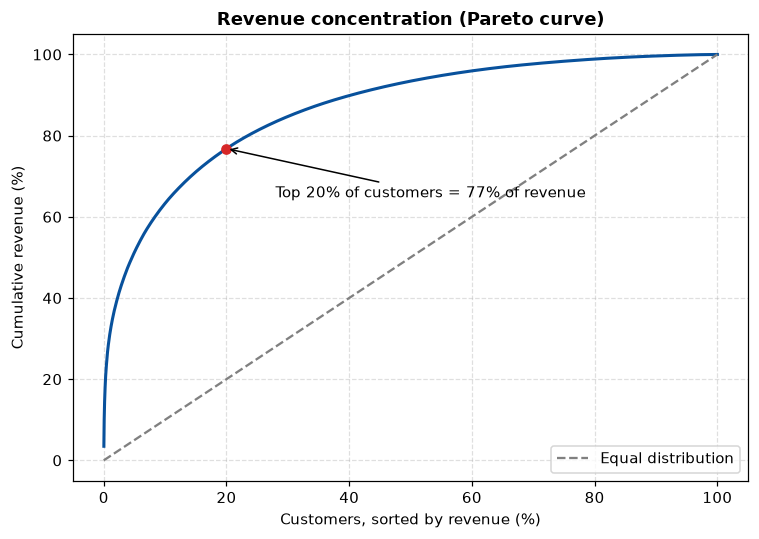

In [16]:
cust_rev = np.sort(sql("SELECT SUM(revenue) AS r FROM sales GROUP BY customer_id")["r"].values)[::-1]
cum_share = np.cumsum(cust_rev) / cust_rev.sum() * 100
pop_share = np.arange(1, len(cust_rev) + 1) / len(cust_rev) * 100

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(pop_share, cum_share, color="#08519c", linewidth=2)
ax.plot([0, 100], [0, 100], color="grey", linestyle="--", label="Equal distribution")
top20 = cum_share[int(len(cust_rev) * 0.2) - 1]
ax.scatter([20], [top20], color="#d62728", zorder=3)
ax.annotate(f"Top 20% of customers = {top20:.0f}% of revenue", (20, top20),
            xytext=(28, top20 - 12), arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("Customers, sorted by revenue (%)")
ax.set_ylabel("Cumulative revenue (%)")
ax.set_title("Revenue concentration (Pareto curve)", fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(IMG_DIR / "pareto.png", bbox_inches="tight")
plt.show()

## 8. Returns

In [17]:
sql("""
SELECT ROUND(SUM(returned_value), 0)                                         AS returned_value,
       ROUND(100 * SUM(returned_value) / (SELECT SUM(revenue) FROM sales), 2) AS returned_pct_of_sales,
       COUNT(DISTINCT invoice)                                               AS return_invoices,
       COUNT(DISTINCT customer_id)                                           AS customers_with_returns,
       ROUND(100.0 * COUNT(DISTINCT customer_id)
             / (SELECT COUNT(DISTINCT customer_id) FROM sales), 1)          AS pct_customers_with_returns
FROM returns
""")

,returned_value,returned_pct_of_sales,return_invoices,customers_with_returns,pct_customers_with_returns
0,"397,726.00",2.37,7028,2377,40.60


In [18]:
# Products with the highest return rate by value, among products with at least £5,000 in sales
sql("""
WITH s AS (SELECT stock_code, ANY_VALUE(description) AS description, SUM(revenue) AS sold
           FROM sales GROUP BY stock_code),
r AS (SELECT stock_code, SUM(returned_value) AS returned FROM returns GROUP BY stock_code)
SELECT s.stock_code, s.description,
       ROUND(s.sold, 0)                             AS sold,
       ROUND(COALESCE(r.returned, 0), 0)            AS returned,
       ROUND(100 * COALESCE(r.returned, 0) / s.sold, 1) AS return_rate_pct
FROM s LEFT JOIN r USING (stock_code)
WHERE s.sold >= 5000
ORDER BY return_rate_pct DESC
LIMIT 10
""")

,stock_code,description,sold,returned,return_rate_pct
0,23113,PANTRY CHOPPING BOARD,"5,696.00","4,803.00",84.30
1,85220,SMALL FAIRY CAKE FRIDGE MAGNETS,"6,875.00","3,646.00",53.00
2,79323W,WHITE CHERRY LIGHTS,"17,123.00","6,257.00",36.50
3,22341,LOVE GARLAND PAINTED ZINC,"5,253.00","1,858.00",35.40
4,79323LP,LIGHT PINK CHERRY LIGHTS,"8,049.00","2,572.00",32.00
5,79323P,PINK CHERRY LIGHTS,"12,937.00","3,891.00",30.10
6,21735,TWO DOOR CURIO CABINET,"8,960.00","2,536.00",28.30
7,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,"23,285.00","6,577.00",28.20
8,22670,FRENCH WC SIGN BLUE METAL,"5,136.00","1,341.00",26.10
9,22656,VINTAGE BLUE KITCHEN CABINET,"9,165.00","2,244.00",24.50


## 9. Markets outside the UK

In [19]:
countries = sql("""
SELECT country,
       COUNT(DISTINCT customer_id)                              AS customers,
       ROUND(SUM(revenue), 0)                                   AS revenue,
       ROUND(100 * SUM(revenue) / SUM(SUM(revenue)) OVER (), 1) AS revenue_share_pct,
       ROUND(SUM(revenue) / COUNT(DISTINCT customer_id), 0)     AS revenue_per_customer
FROM sales
GROUP BY country
QUALIFY ROW_NUMBER() OVER (ORDER BY SUM(revenue) DESC) <= 10
ORDER BY revenue DESC
""")
countries

,country,customers,revenue,revenue_share_pct,revenue_per_customer
0,United Kingdom,5333,"13,981,647.00",83.50,"2,622.00"
1,EIRE,3,"578,531.00",3.50,"192,844.00"
2,Netherlands,22,"549,773.00",3.30,"24,990.00"
3,Germany,107,"383,169.00",2.30,"3,581.00"
4,France,93,"308,166.00",1.80,"3,314.00"
5,Australia,15,"167,582.00",1.00,"11,172.00"
6,Spain,38,"97,767.00",0.60,"2,573.00"
7,Switzerland,22,"93,011.00",0.60,"4,228.00"
8,Sweden,19,"85,807.00",0.50,"4,516.00"
9,Denmark,12,"67,423.00",0.40,"5,619.00"


## 10. Conclusions

1. **Strong seasonality, no growth.** September to November brings about 40% of the year's revenue (£3.05M of £7.55M in January–November 2011). Year over year, January–November revenue changed by −0.9% and active customers by +1%. The business is stable but not growing.
2. **Retention is low at first, then flat.** On average only about 21% of a cohort buys again in the following month. But the curve barely drops after that: about 18% still buy in month 12. Customers who come back a second time usually stay, so the main lever is the second purchase.
3. **Revenue is highly concentrated.** The top 20% of customers bring 77% of revenue and the top 1% bring 31%. The *Champions* segment is 23% of customers and 70% of revenue.
4. **A clear reactivation target.** The *Cannot lose them* segment has 224 customers who used to buy often (9 orders on average, £4.4k each), but their last purchase was about 340 days ago. Together they spent £0.98M, so winning back even part of them matters more than most acquisition campaigns.
5. **Cleaning changes the conclusions.** Without removing order-entry errors, the return rate would be 4.2% of sales. After removing 1,039 lines that were entered and cancelled within an hour (£318k), the real return rate is **2.4%**. A few products stand out: the *cherry lights* range has 30–37% returned by value, which is worth a quality check.
6. **International revenue relies on a few key accounts.** The UK brings 83.5% of revenue. Ireland (EIRE) gives £579k from only 3 customers and the Netherlands £550k from 22, so losing one account would be visible in the totals.

### Limitations
- Rows without a customer ID (about 23% of raw rows) are excluded, so customer-level revenue is lower than the shop's total revenue.
- The December 2009 cohort includes customers who were already buying before the data starts.
- Many customers are wholesalers, so their order values and frequency are very different from typical retail shoppers.
- RFM segment rules are a common convention, not something fitted to this data.